# Stage 6b: Forecasting games before they are played

Stage 6 looked back at played games with their real shots. Here the question is practical: **before** a game, can the
shot model forecast who wins, and does it beat simple forecasts?

Nothing from the game itself is used. For each team the profile is built from its **previous K games** (they may reach
into the previous season):
- attack: possessions with a shot (chains) per game, the pool of first shots and of putbacks with their p and value,
  offensive rebound rate, free throws made per game, shot making (points per shot above xPTS, shrunk);
- defence: the same quantities allowed to opponents.

Attack of one team and defence of the other are combined around the league average of the previous season, e.g.
chains = attack_A + allowed_B − league. One simulation (`forecast_games`): the expected number of chains and FTM, shots
drawn from the pools, made with p + (shot making of A + shot making allowed by B)/v, putbacks after misses, plus a home
advantage of h points. 10,000 simulations per game.

Protocol:
- **development seasons 2023-24 and 2024-25**: choose K, the shrinkage constant and h, fit the baselines;
- **2025-26 once**, nothing changed after seeing it (as in `09_holdout`). The shots of 2025-26 enter a profile only
  after the game they were taken in.

Baselines: home team (constant), recent win share (logistic), recent point differential (logistic), Elo
(FiveThirtyEight-style, K = 20, home +100).

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression

from xpts.forecast import elo_ratings, forecast_games, rolling_profiles, team_game_table
from xpts.metrics import paired_bootstrap
from xpts.players import fit_prior
from xpts.simulation import load_games

FIG_DIR = Path("../reports/figures")
P = "../data/processed/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DEV, HOLD = ["2023-24", "2024-25"], "2025-26"

s1, g1, _ = load_games(P + "oos_predictions.parquet", P + "shots_features.parquet", P + "shots_context.parquet", "../data/raw/games")
s2, g2, _ = load_games(P + "holdout_predictions.parquet", P + "shots_features.parquet", P + "shots_context.parquet", "../data/raw/games")
shots = pd.concat([s1, s2], ignore_index=True)
games = pd.concat([g1, g2], ignore_index=True).sort_values(["GAME_DATE", "GAME_ID"]).reset_index(drop=True)
tg = team_game_table(shots, games)
dev = games[games["SEASON"].isin(DEV)]
hold = games[games["SEASON"] == HOLD]
print(f"{len(games):,} games with shots ({len(dev)} development, {len(hold)} hold-out), {len(tg):,} team-games")


def ll(y, p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    y = np.asarray(y)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def scores(y, p):
    return {"log loss": ll(y, p), "Brier": float(np.mean((np.asarray(p) - y) ** 2)),
            "accuracy": float(np.mean((np.asarray(p) > 0.5) == y))}

13,106 games with shots (2455 development, 1225 hold-out), 26,212 team-games


## 1. Shrinkage of team shot making

A team's points above xPTS over K games mixes skill and luck, exactly as for players in Stage 5. The same empirical
Bayes model gives τ² (true spread between teams) and k = σ² / τ² (shots at which the estimate is half signal).
Fitted on full team-seasons 2015-16 to 2022-23 (before the development seasons), in attack and in defence.

In [2]:
base = tg[tg["SEASON"] < DEV[0]]
k_vals = {}
for name, r, n, v in [("attack", "r", "shots", "var"), ("defence", "r_allowed", "shots_allowed", "var_allowed")]:
    ts = base.groupby(["SEASON", "TEAM_ID"])[[r, n, v]].sum()
    sm = ts[r] / ts[n] - (ts[r].groupby("SEASON").transform("sum") / ts[n].groupby("SEASON").transform("sum"))
    s2 = ts[v] / ts[n] ** 2
    f = fit_prior(sm, s2)
    sigma2 = (ts[v] / ts[n]).mean()
    k_vals[name] = sigma2 / f["tau2"]
    print(f"{name}: tau = {np.sqrt(f['tau2']):.4f} points/shot, k = {k_vals[name]:.0f} shots "
          f"(about {k_vals[name] / ts[n].mean() * 82:.0f} games)")
K_SHRINK = float(np.mean(list(k_vals.values())))
print(f"k used for both: {K_SHRINK:.0f} shots")

attack: tau = 0.0321 points/shot, k = 1266 shots (about 15 games)
defence: tau = 0.0252 points/shot, k = 2052 shots (about 25 games)
k used for both: 1659 shots


**Observations.**
- True team shot making differs between teams by τ ≈ 0.032 points per shot in attack and 0.025 in defence (smaller
  than between players, 0.071, because a team averages its players).
- k is 1,266 shots in attack (about 15 games) and 2,052 in defence (about 25 games): defence shot making is noisier and
  needs more games. The forecast uses the mean, k = 1,659 shots: with K = 40 games (about 3,500 shots) a team's own shot
  making gets weight about 0.68.

## 2. Development: window K and home advantage

Forecasts for all games of 2023-24 and 2024-25 with h = 0 and K ∈ {10, 20, 40, 82} (2,000 simulations each). The home
advantage h is the mean of (actual − forecast margin) on development games; the best K is the one with the lowest log
loss after adding h. Raw Monte Carlo probabilities can be too wide or too narrow, so a **calibrated** version maps the
expected margin to P(win) by a logistic regression fitted on the development games.

In [3]:
dev_fc = {}
rows = []
for K in [10, 20, 40, 82]:
    f = forecast_games(dev, shots, tg, K=K, k_shrink=K_SHRINK, h=0.0, n_sims=2000, seed=K)
    h = float((f["margin"] - f["xmargin"]).mean())
    f2 = forecast_games(dev, shots, tg, K=K, k_shrink=K_SHRINK, h=h, n_sims=2000, seed=K)
    dev_fc[K] = (h, f2)
    rows.append({"K": K, "h": h, **scores(f2["home_win"], f2["p_home"]),
                 "corr(xmargin, margin)": np.corrcoef(f2["xmargin"], f2["margin"])[0, 1],
                 "forecast sd": f2["sd_margin"].mean(), "sd(margin - xmargin)": (f2["margin"] - f2["xmargin"]).std()})
dev_res = pd.DataFrame(rows).set_index("K")
display(dev_res.round(4))
K_BEST = int(dev_res["log loss"].idxmin())
H_BEST, f_dev = dev_fc[K_BEST]
cal = LogisticRegression(C=1e6).fit(f_dev[["xmargin"]], f_dev["home_win"])
print(f"chosen K = {K_BEST}, h = {H_BEST:.2f} points; calibration: logit P = {cal.intercept_[0]:.3f} + {cal.coef_[0, 0]:.4f} * xmargin "
      f"(equivalent normal sd of the margin about {1.7 / cal.coef_[0, 0]:.1f})")

,h,log loss,Brier,accuracy,"corr(xmargin, margin)",forecast sd,sd(margin - xmargin)
K,,,,,,,
10,1.9718,0.6456,0.2274,0.6224,0.3427,15.2115,14.8402
20,2.0303,0.6339,0.2219,0.6387,0.3854,15.2152,14.5252
40,1.9652,0.6306,0.2206,0.6354,0.3885,15.1991,14.5022
82,1.9468,0.6343,0.2223,0.6293,0.3684,15.1596,14.6319


chosen K = 40, h = 1.97 points; calibration: logit P = -0.033 + 0.1202 * xmargin (equivalent normal sd of the margin about 14.1)


**Observations.**
- K = 40 games is the best window (log loss 0.6306); 10 games is too noisy (0.6456), a whole season too slow (0.6343).
- The home advantage is h ≈ 2.0 points (the profiles mix home and away games, so the forecast without h is neutral).
- The Monte Carlo spread is slightly too wide: the forecast sd of the margin is 15.2 points, the real error sd 14.5.
  The calibrated version (logistic on the expected margin) corresponds to a normal sd of about 14.1.
- The expected margin correlates 0.39 with the actual margin, the same level as the retrospective expected margin of
  Stage 6 (0.39), although no shot of the game is known.

## 3. Baselines

- **Home**: P = home win share of the development seasons.
- **Win share**: logistic regression on (win share of the last K games of home − of away).
- **Point differential**: logistic regression on (mean point differential of the last K games of home − of away).
- **Elo**: ratings from all games since 2014-15 (box scores), updated after each game; K = 20, home +100 Elo points,
  75% carried over between seasons, no margin-of-victory term. Fixed parameters, not tuned.
K for the two logistic baselines is chosen on the development seasons in the same way.

In [4]:
# Elo from the box scores (all games, including those dropped for missing shots)
box = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob("../data/raw/games/games_*.parquet"))])
box = box[box.groupby("GAME_ID")["TEAM_ID"].transform("size") == 2]   # games with exactly two team rows
bh = box[box["MATCHUP"].str.contains("vs.")][["GAME_ID", "SEASON", "GAME_DATE", "TEAM_ID", "PTS"]]
ba = box[~box["MATCHUP"].str.contains("vs.")][["GAME_ID", "TEAM_ID", "PTS"]]
eg = bh.merge(ba, on="GAME_ID", suffixes=("_home", "_away"))
eg["GAME_DATE"] = pd.to_datetime(eg["GAME_DATE"])
print(f"Elo input: {len(eg):,} games {eg['SEASON'].min()} to {eg['SEASON'].max()}")
elo = elo_ratings(eg)

home_rate = dev["home_win"].mean()
base_fit, base_rows = {}, []
for K in [10, 20, 40, 82]:
    pr = rolling_profiles(tg, K).set_index(["GAME_ID", "TEAM_ID"])
    feats = {}
    for name, df in [("dev", dev), ("hold", hold)]:
        ph = pr.loc[list(zip(df["GAME_ID"], df["TEAM_ID_home"]))].reset_index(drop=True)
        pa = pr.loc[list(zip(df["GAME_ID"], df["TEAM_ID_away"]))].reset_index(drop=True)
        feats[name] = pd.DataFrame({"win_diff": ph["win"] / ph["n_games"] - pa["win"] / pa["n_games"],
                                    "net_diff": (ph["pts"] - ph["pts_allowed"]) / ph["n_games"] - (pa["pts"] - pa["pts_allowed"]) / pa["n_games"]})
    for col in ["win_diff", "net_diff"]:
        m = LogisticRegression(C=1e6).fit(feats["dev"][[col]], dev["home_win"])
        p_dev = m.predict_proba(feats["dev"][[col]])[:, 1]
        base_rows.append({"baseline": col, "K": K, "dev log loss": ll(dev["home_win"], p_dev)})
        base_fit[(col, K)] = m.predict_proba(feats["hold"][[col]])[:, 1]
base_res = pd.DataFrame(base_rows)
display(base_res.pivot(index="K", columns="baseline", values="dev log loss").round(4))
best_base = base_res.loc[base_res.groupby("baseline")["dev log loss"].idxmin()].set_index("baseline")["K"]
print("chosen K:", best_base.to_dict())
e_dev = dev.merge(elo, on="GAME_ID")
print(f"Elo on development seasons: log loss {ll(e_dev['home_win'], e_dev['p_elo']):.4f}; "
      f"home constant {ll(dev['home_win'], np.full(len(dev), home_rate)):.4f}")

Elo input: 14,429 games 2014-15 to 2025-26


baseline,net_diff,win_diff
K,,
10,0.6276,0.6394
20,0.6178,0.6250
40,0.6156,0.6171
82,0.6210,0.6204


chosen K: {'net_diff': 40, 'win_diff': 40}
Elo on development seasons: log loss 0.6286; home constant 0.6893


**Observations.**
- On the development seasons the simple baselines are strong: point differential of the last 40 games 0.6156, win share
  0.6171, Elo 0.6286, the shot model 0.6306. Always picking the home team: 0.6893.
- The shot model was **worse** than point differential on development data. It is still run on 2025-26 unchanged, as
  planned; nothing is selected on the hold-out.

## 4. Hold-out 2025-26 (run once)

All choices above are frozen. Forecasts with K = K_BEST, h = H_BEST, 10,000 simulations; Stage 6's retrospective
P(win) (which knows the real shots of the game) is shown as an upper reference, not a forecast.

In [5]:
fh = forecast_games(hold, shots, tg, K=K_BEST, k_shrink=K_SHRINK, h=H_BEST, n_sims=10_000, seed=2026)
fh["p_mc_cal"] = cal.predict_proba(fh[["xmargin"]])[:, 1]
fh = fh.merge(elo, on="GAME_ID", how="left")
fh["p_home_const"] = home_rate
fh["p_win_share"] = base_fit[("win_diff", int(best_base["win_diff"]))]
fh["p_net"] = base_fit[("net_diff", int(best_base["net_diff"]))]
retro = pd.read_parquet(P + "game_simulations_holdout.parquet")[["GAME_ID", "p_win_mc"]].rename(columns={"p_win_mc": "p_retro"})
fh = fh.merge(retro, on="GAME_ID", how="left")
fh.to_parquet(P + "forecast_holdout.parquet")

models = {"p_home": "Shot model Monte Carlo", "p_mc_cal": "Shot model Monte Carlo, calibrated", "p_elo": "Elo",
          "p_net": "Point differential", "p_win_share": "Win share", "p_home_const": "Home team",
          "p_retro": "Retrospective (real shots, not a forecast)"}
res = pd.DataFrame({lab: scores(fh["home_win"], fh[c]) for c, lab in models.items()}).T
display(res.round(4))

,log loss,Brier,accuracy
Shot model Monte Carlo,0.6125,0.2116,0.6620
"Shot model Monte Carlo, calibrated",0.6109,0.2107,0.6604
Elo,0.6178,0.2136,0.6669
Point differential,0.6088,0.2097,0.6816
Win share,0.6165,0.2132,0.6751
Home team,0.6875,0.2472,0.5543
"Retrospective (real shots, not a forecast)",0.5759,0.1966,0.6971


In [6]:
# paired bootstrap of the log loss difference per game (1000 resamples of games); negative = shot model better
cmp = {}
for c in ["p_elo", "p_net", "p_win_share", "p_home_const"]:
    for mine in ["p_home", "p_mc_cal"]:
        cmp[f"{models[mine]} - {models[c]}"] = paired_bootstrap(fh["home_win"], fh[mine], fh[c], fh["GAME_ID"])
display(pd.DataFrame(cmp).T.round(5))
# does the shot model add information to Elo? logistic regression of the result on both (in-sample on 2025-26, descriptive)
X = pd.DataFrame({"elo": np.log(fh["p_elo"] / (1 - fh["p_elo"])), "shot": np.log(fh["p_mc_cal"] / (1 - fh["p_mc_cal"]))})
m1 = LogisticRegression(C=1e6).fit(X[["elo"]], fh["home_win"])
m2 = LogisticRegression(C=1e6).fit(X, fh["home_win"])
ll1 = -ll(fh["home_win"], m1.predict_proba(X[["elo"]])[:, 1]) * len(X)
ll2 = -ll(fh["home_win"], m2.predict_proba(X)[:, 1]) * len(X)
lr = 2 * (ll2 - ll1)
print(f"Elo + shot model: coefficients elo {m2.coef_[0, 0]:.3f}, shot {m2.coef_[0, 1]:.3f}; "
      f"likelihood ratio test for adding the shot model: LR = {lr:.2f}, p = {stats.chi2.sf(lr, 1):.4f}")

,diff,ci_low,ci_high,share_a_better
Shot model Monte Carlo - Elo,-0.00534,-0.02157,0.01089,0.730
"Shot model Monte Carlo, calibrated - Elo",-0.00699,-0.02218,0.00932,0.792
Shot model Monte Carlo - Point differential,0.00371,-0.00392,0.01149,0.183
"Shot model Monte Carlo, calibrated - Point differential",0.00207,-0.00504,0.00954,0.277
Shot model Monte Carlo - Win share,-0.00405,-0.01387,0.00564,0.778
"Shot model Monte Carlo, calibrated - Win share",-0.00569,-0.01585,0.00451,0.862
Shot model Monte Carlo - Home team,-0.07496,-0.09472,-0.05563,1.000
"Shot model Monte Carlo, calibrated - Home team",-0.07661,-0.09869,-0.05536,1.000


Elo + shot model: coefficients elo 0.638, shot 0.475; likelihood ratio test for adding the shot model: LR = 11.14, p = 0.0008


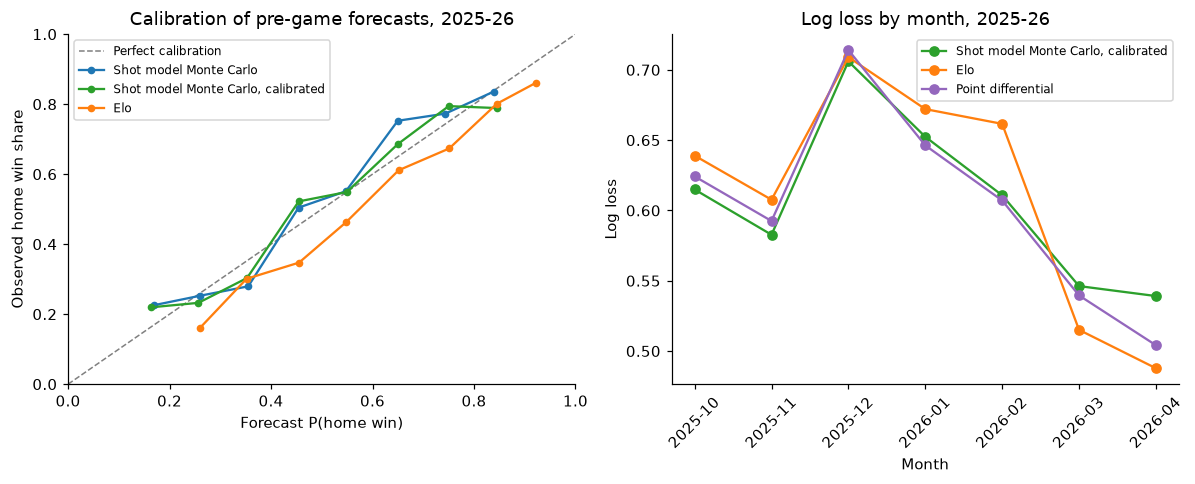

,p_mc_cal,p_elo,p_net
month,,,
2025-10,0.6149,0.6390,0.6242
2025-11,0.5827,0.6076,0.5925
2025-12,0.7060,0.7091,0.7141
2026-01,0.6524,0.6721,0.6463
2026-02,0.6108,0.6616,0.6071
2026-03,0.5462,0.5151,0.5396
2026-04,0.5391,0.4878,0.5041


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bins = np.linspace(0, 1, 11)
ax = axes[0]
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Perfect calibration")
for c, col in [("p_home", "tab:blue"), ("p_mc_cal", "tab:green"), ("p_elo", "tab:orange")]:
    t = fh.assign(b=pd.cut(fh[c], bins, include_lowest=True)).groupby("b", observed=True).agg(p=(c, "mean"), o=("home_win", "mean"), n=(c, "size"))
    t = t[t["n"] >= 20]
    ax.plot(t["p"], t["o"], "o-", color=col, ms=4, label=models[c])
ax.set(xlabel="Forecast P(home win)", ylabel="Observed home win share", xlim=(0, 1), ylim=(0, 1),
       title="Calibration of pre-game forecasts, 2025-26")
ax.legend(fontsize=8)
ax = axes[1]
fh["month"] = fh["GAME_DATE"].dt.to_period("M").astype(str)
mon = fh.groupby("month").apply(lambda q: pd.Series({c: ll(q["home_win"], q[c]) for c in ["p_mc_cal", "p_elo", "p_net"]}), include_groups=False)
for c, col in [("p_mc_cal", "tab:green"), ("p_elo", "tab:orange"), ("p_net", "tab:purple")]:
    ax.plot(mon.index, mon[c], "o-", color=col, label=models[c])
ax.set(xlabel="Month", ylabel="Log loss", title="Log loss by month, 2025-26")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "06b_forecast.pdf")
plt.show()
display(mon.round(4))

**Observations.**
- **2025-26 (1,225 games): the shot model forecasts as well as the standard methods.** Log loss 0.6125 (calibrated
  0.6109), Brier 0.212, accuracy 66%; Elo 0.6178, win share 0.6165, point differential 0.6088 (best), home team 0.6875.
- None of the differences between the shot model and Elo, win share or point differential is significant: e.g.
  calibrated − Elo −0.0070 [−0.0222; 0.0093], calibrated − point differential +0.0021 [−0.0050; 0.0095]. One season is
  too short to separate methods whose log losses differ by less than 0.01. The shot model is clearly better than the
  home-team rule (−0.077 [−0.099; −0.055]).
- **The shot model carries information Elo does not have**: in a logistic regression on both forecasts the shot model
  keeps a clear coefficient (0.48 next to 0.64 for Elo), likelihood ratio test p = 0.0008 (in-sample on 2025-26, so
  descriptive). Shot quality and results-based ratings are partly complementary.
- Calibration: the shot model is close to the diagonal; Elo overrates the home team (its fixed +100 Elo points is more
  than the current home advantage of about 2 points).
- By month the methods move together; December is hard for all (log loss 0.71). Early in the season (October,
  November), when profiles still rely on the previous season, the shot model is the best of the three.
- **Upper reference**: knowing the real shots of the game (Stage 6) gives log loss 0.576 and accuracy 70%. The gap
  between 0.611 and 0.576 is the information about the game itself that no pre-game forecast can have.

## 5. Summary

- A fully generative pre-game Monte Carlo built only from xPTS profiles of the last 40 games (shot pools, putbacks,
  free throws, shrunk team shot making in attack and defence, home advantage 2 points) forecasts NBA games of 2025-26
  with log loss 0.611-0.613 and accuracy 66%.
- This is at the level of the standard methods (Elo 0.618, win share 0.617, point differential 0.609); the differences are
  not significant on one season. On development seasons the shot model was slightly worse than point differential.
- The shot model contains information that Elo does not (LR test p < 0.001), so combining them is a natural next step.
- Limits: profiles ignore injuries, trades and rest; the number of possessions and free throws are taken at their
  expected values; the defence effect is additive; one hold-out season.

Figure: `06b_forecast.pdf`.